# Supplementary Fig. 1a: morpho-electrical combinations of the model neurons

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of Supplementary Fig. 1 of the paper: the combinations of neuron morphologies (m-types, rows), electrical firing patterns (e-types, columns) and their proportions (heatmap colours) in the model; the inhibitory parvalbumin-positive (PV+, blue bar), somatostatin-positive (Sst+, green bar) and 5HT3aR+ (orange bar) classes are on the side; the cACint electrical types of the Sst+ class are in green boxes. Source data and svg are saved in figures/8_source_data/supp_fig1a/.

**method: the values are read from the paper's figure**
* the panel is adapted from the model's reference publication ([30] of the paper); this repository does not contain the model's cell composition, so the proportions cannot be computed from the data of the study. (The 1,836 neurons of the evoked ground truth cover only 48 of the 60 m-types.)
* the proportion of each combination is therefore **digitised from the heatmap of the paper's pdf** (page 39 of `paper/Laquitaine_NatureNeuro_2025.pdf`, an embedded 411 x 991 pixel image): the colour of the centre of each of the 60 x 11 cells is converted into a proportion with the colour bar of the same image. Cells without colour (no neuron with this combination) are empty
* check: the proportions of the e-types of an m-type should add up to 1. After digitisation they add up to 1.00 for the 18 excitatory m-types and to 1.00 to 1.06 for the inhibitory ones. The values are approximate (about +-0.05, mostly for the dark cells whose colours are close to each other); the column `proportion_normalised` divides each value by the sum of its m-type
* the exact values must come from the cell composition of the model ([30]) if they are required as source data

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import subprocess
import tempfile
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

# paths
PDF_PATH = "paper/Laquitaine_NatureNeuro_2025.pdf"
PDF_PAGE = 39          # Supplementary Fig. 1

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Extract the heatmap of the paper's figure

In [3]:
%%time

# the heatmap is an embedded image (411 x 991 pixels) of page 39
with tempfile.TemporaryDirectory() as tmp:
    subprocess.run(["pdfimages", "-png", "-f", str(PDF_PAGE), "-l", str(PDF_PAGE), PDF_PATH, tmp + "/img"], check=True)
    image = np.array(Image.open(tmp + "/img-000.png").convert("RGB")).astype(float)
print("image size:", image.shape)

image size: (991, 411, 3)
CPU times: user 9.2 ms, sys: 7.09 ms, total: 16.3 ms
Wall time: 72.7 ms


## Digitise the proportions

In [4]:
%%time

M_TYPES = """L2_IPC L2_TPC:A L2_TPC:B L3_TPC:A L3_TPC:C L4_SSC L4_TPC L4_UPC L5_TPC:A L5_TPC:B L5_TPC:C L5_UPC L6_BPC L6_HPC L6_IPC L6_TPC:A L6_TPC:C L6_UPC
L23_LBC L23_NBC L23_CHC L4_LBC L4_NBC L4_CHC L5_LBC L5_NBC L5_CHC L6_LBC L6_NBC L6_CHC L23_MC L4_MC L5_MC L6_MC L1_DAC L1_HAC L1_LAC L1_NGC-DA L1_NGC-SA L1_SAC
L23_BP L23_BTC L23_DBC L23_NGC L23_SBC L4_BP L4_BTC L4_DBC L4_NGC L4_SBC L5_BP L5_BTC L5_DBC L5_NGC L5_SBC L6_BP L6_BTC L6_DBC L6_NGC L6_SBC""".split()      # rows, top to bottom
E_TYPES = "bIR cIR dSTUT bSTUT cSTUT dNAC bNAC cNAC bAC cACint cADpyr".split()      # columns, left to right
assert len(M_TYPES) == 60 and len(E_TYPES) == 11

# geometry of the heatmap in the image (pixels): 11 columns of equal width, 60 rows of equal height; colour bar (0 to 1) under the heatmap
X0, X1, Y0, ROW_HEIGHT = 149.0, 395.5, 110.5, 13.32
COLORBAR_ROW = 947
col_width = (X1 - X0) / len(E_TYPES)
bar_x = np.arange(150, 395)
bar_colors = np.array([image[COLORBAR_ROW, x] for x in bar_x])
bar_values = (bar_x + 0.5 - X0) / (X1 - X0)

rows = []
for i, m_type in enumerate(M_TYPES):
    for j, e_type in enumerate(E_TYPES):
        xc, yc = X0 + (j + 0.5) * col_width, Y0 + (i + 0.5) * ROW_HEIGHT
        colour = np.median(image[int(yc - 2.5):int(yc + 3.5), int(xc - 6):int(xc + 7)].reshape(-1, 3), axis=0)
        if colour.min() > 235:
            continue                       # white: no neuron with this combination
        rows.append(dict(m_type=m_type, e_type=e_type, proportion_digitised=bar_values[np.argmin(((bar_colors - colour) ** 2).sum(axis=1))]))
df = pd.DataFrame(rows)
df["proportion_normalised"] = df["proportion_digitised"] / df.groupby("m_type")["proportion_digitised"].transform("sum")

# neuron class of each m-type: rows of the side bars of the figure
def neuron_class(m_type):
    i = M_TYPES.index(m_type)
    return "excitatory" if i < 18 else "PV+" if i < 30 else "Sst+" if i < 34 else "5HT3aR+"
df["neuron_class"] = df["m_type"].map(neuron_class)
df["row"] = df["m_type"].map(M_TYPES.index); df["column"] = df["e_type"].map(E_TYPES.index)
sums = df.groupby("m_type")["proportion_digitised"].sum()
print("combinations:", len(df), "| sum of the proportions per m-type: from", sums.min().round(2), "to", sums.max().round(2))
display(df.head())

combinations: 212 | sum of the proportions per m-type: from 1.0 to 1.06


,m_type,e_type,proportion_digitised,proportion_normalised,neuron_class,row,column
0,L2_IPC,cADpyr,0.995943,1.0,excitatory,0,10
1,L2_TPC:A,cADpyr,0.995943,1.0,excitatory,1,10
2,L2_TPC:B,cADpyr,0.995943,1.0,excitatory,2,10
3,L3_TPC:A,cADpyr,0.995943,1.0,excitatory,3,10
4,L3_TPC:C,cADpyr,0.995943,1.0,excitatory,4,10


CPU times: user 12.1 ms, sys: 3.01 ms, total: 15.1 ms
Wall time: 15.1 ms


## Plot, same as the paper's panel

In [5]:
# colour map of the figure: the colour bar of the paper's image
COLORMAP = ListedColormap(bar_colors / 255.0)
CLASS_COLORS = {"PV+": tuple(image[430, 405] / 255), "Sst+": tuple(image[540, 405] / 255), "5HT3aR+": tuple(image[730, 405] / 255)}
print({k: np.round(v, 2) for k, v in CLASS_COLORS.items()})

def plot_source_data(df: pd.DataFrame):
    """Proportion of each e-type (columns) for each m-type (rows); colour bar below; PV+, Sst+ and 5HT3aR+ classes on the right (bars); green boxes: cACint of the Sst+ class"""

    m_types = [m for m in df.sort_values("row")["m_type"].unique()]
    e_types = [e for e in df.sort_values("column")["e_type"].unique()]
    matrix = np.full((len(m_types), len(e_types)), np.nan)
    for r in df.itertuples():
        matrix[m_types.index(r.m_type), e_types.index(r.e_type)] = r.proportion_digitised

    fig, ax = plt.subplots(1, 1, figsize=(2.7, 6.4))
    mesh = ax.pcolormesh(np.ma.masked_invalid(matrix), cmap=COLORMAP, vmin=0, vmax=1, edgecolors=(1, 1, 1, 0.6), linewidth=0.6)
    ax.set_xlim(0, len(e_types)); ax.set_ylim(len(m_types), 0)

    # ticks and labels
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(len(e_types)) + 0.5); ax.set_xticklabels(e_types, rotation=90, fontsize=5)
    ax.set_yticks(np.arange(len(m_types)) + 0.5); ax.set_yticklabels(m_types, fontsize=4.2)
    ax.tick_params(axis="both", length=2, width=0.4, pad=1)
    ax.set_title("e-types", fontsize=6, pad=24)
    ax.set_ylabel("m-types", fontsize=6)
    for spine in ax.spines.values(): spine.set_visible(False)
    fig.text(0.5, 0.995, "Morpho-electrical combinations", ha="center", va="top", fontsize=6.5, fontweight="bold")

    # neuron classes (bars on the right)
    for cls, (r0, r1) in {"PV+": (18, 30), "Sst+": (30, 34), "5HT3aR+": (34, 60)}.items():
        ax.plot([len(e_types) + 0.35, len(e_types) + 0.35], [r0 + 0.1, r1 - 0.1], color=CLASS_COLORS[cls], linewidth=1.2, clip_on=False)
        ax.text(len(e_types) + 0.8, (r0 + r1) / 2, cls + " neurons", ha="left", va="center", fontsize=5.5, clip_on=False)

    # green boxes around the cACint of the BTC and DBC types
    j = e_types.index("cACint")
    for layer in ["L23", "L4", "L5", "L6"]:
        i0 = m_types.index(f"{layer}_BTC")
        ax.add_patch(Rectangle((j, i0), 1, 2, fill=False, edgecolor=(0.3, 0.65, 0.25), linewidth=1.0, clip_on=False))

    # colour bar
    cax = fig.add_axes([0.355, 0.045, 0.545, 0.012])
    cbar = fig.colorbar(mesh, cax=cax, orientation="horizontal", ticks=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
    cbar.ax.tick_params(labelsize=5, width=0.4, length=1.5); cbar.outline.set_linewidth(0.3)
    cbar.set_label("Proportion (ratio)", fontsize=6, labelpad=2)
    return fig, ax

{'PV+': array([0.19, 0.38, 0.62]), 'Sst+': array([0.33, 0.65, 0.27]), '5HT3aR+': array([0.71, 0.57, 0.18])}


## Plot and save the figure and the source data

CPU times: user 504 ms, sys: 27 ms, total: 531 ms
Wall time: 532 ms


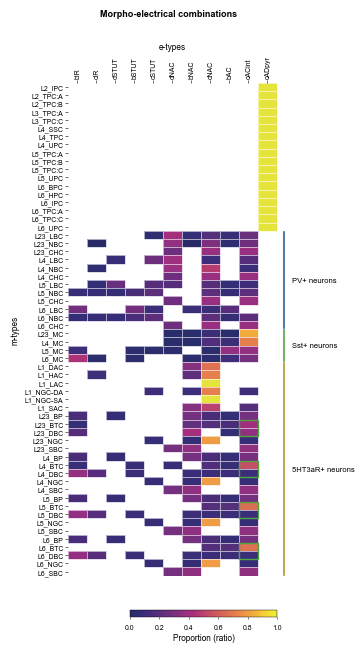

In [6]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/supp_fig1a", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig1a/supp_fig1a.svg", bbox_inches="tight", **savefig_cfg)

# save source data (proportions digitised from the paper's figure)
df.to_excel("figures/8_source_data/supp_fig1a/supp_fig1a.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 46.8 ms, sys: 0 ns, total: 46.8 ms
Wall time: 46.8 ms


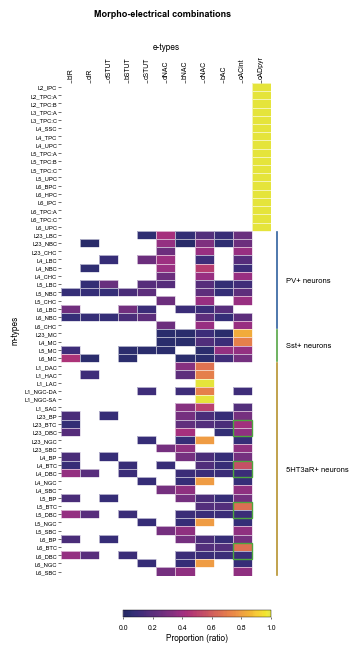

In [7]:
%%time

df = pd.read_excel("figures/8_source_data/supp_fig1a/supp_fig1a.xlsx")
fig, ax = plot_source_data(df)